# Neural v2 Decipherment: Tibbonid Hebrew (Moreh Nevuchim)
## Testing the Neural v2 pipeline against philosophical Hebrew

This notebook replicates the Neural v2 pipeline (notebook 14) but uses the
Moreh Nevuchim corpus (Ibn Tibbon's translation of Maimonides' Guide for the
Perplexed) instead of the Torah. The Moreh Nevuchim represents a different
register of Hebrew: medieval philosophical prose with heavy Arabic influence,
Tibbonid neologisms, and a distinct vocabulary.

### Key differences from nb14:
- **Corpus**: Moreh Nevuchim (157K words full, 37K subsampled) instead of Torah (~80K)
- **LM training**: LSTM trained on the FULL 157K words, but decipherment uses 37K subsample
- **Same pipeline**: Multi-seed EM (20 seeds x 2 temperatures) + MCMC (4 chains) + 5-test validation
- **Comparison**: Side-by-side with Torah-based Neural v2 results

In [8]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cpu
Imports OK


In [9]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):  # parse full STA file
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── Segmentation and positional classification ──

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Load and process Voynich ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification: C={n_c}, V={n_v}, ?={n_q}')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs
Classification: C=70, V=5, ?=91


In [10]:
# ── Cell 3: Load Moreh Nevuchim corpus + CharLM baseline + grammar anchors ──

import json as _json

with open('corpus/moreh_nevuchim_processed.json', 'r', encoding='utf-8') as f:
    mn_data = _json.load(f)

print(f'Source: {mn_data["source"]}')

# words_full = ALL 157K words (for LM training)
# hebrew_words = subsampled 37K (for decipherment mapping)
hebrew_words_full = [list(w) for w in mn_data['words_full']]
hebrew_words = [list(w) for w in mn_data['words']]

# Filter word lengths (same as nb14)
hebrew_words_full = [w for w in hebrew_words_full if 2 <= len(w) <= 15]
hebrew_words = [w for w in hebrew_words if 2 <= len(w) <= 15]

print(f'Moreh Nevuchim full corpus: {len(hebrew_words_full):,} words')
print(f'Moreh Nevuchim subsampled:  {len(hebrew_words):,} words')

# Hebrew C/V classification (matres lectionis)
HEBREW_VOWELS = set('אהוי')  # alef, he, vav, yod
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew chars: {len(target_chars_heb)} (C={n_c_h}, V={n_v_h})')

# Also use char_role from the JSON if available (should match)
if 'char_role' in mn_data:
    char_role_json = mn_data['char_role']
    mismatches = sum(1 for c in target_chars_heb
                     if c in char_role_json and char_role_json[c] != char_role_heb[c])
    print(f'C/V role mismatches with JSON: {mismatches}')

# ── Trigram CharLM baseline (Witten-Bell) ──
class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp, total_n = 0.0, 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

# Train baseline on subsampled words
char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words)
print(f'CharLM baseline native PPX (subsampled): {ppx_baseline:.2f}')

# ── Grammar anchors ──
HEBREW_PREFIXES = set('והבכלמש')  # והבכלמש
HEBREW_SUFFIXES = set('התםןך')  # התםןך
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

Source: Moreh Nevuchim (Ibn Tibbon translation), Sefaria Makbili Edition 2024
Moreh Nevuchim full corpus: 157,042 words
Moreh Nevuchim subsampled:  37,087 words
Hebrew chars: 27 (C=23, V=4)
C/V role mismatches with JSON: 0
CharLM baseline native PPX (subsampled): 8.25

Grammar anchors: 12 glyphs
  root: 7
  suffix: 2
  prefix: 2
  classifier: 1


In [11]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocabulary from FULL corpus (for LM training) ──
all_chars_heb = sorted(set(c for w in hebrew_words_full for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 31 tokens (27 chars + 4 special)
Parameters: 476,991


Train: 125,634 words, Val: 31,408 words
Train samples: 652,959, Val samples: 163,075

Training Neural LM on FULL Moreh Nevuchim (30 epochs, patience=5)...
  Epoch  1: train_loss=2.2646, val_loss=2.1498, lr=0.001995
  Epoch  5: train_loss=2.1448, val_loss=2.1232, lr=0.001866
  Epoch 10: train_loss=2.1336, val_loss=2.1168, lr=0.001500
  Epoch 15: train_loss=2.1265, val_loss=2.1121, lr=0.001000
  Epoch 20: train_loss=2.1204, val_loss=2.1089, lr=0.000500
  Epoch 25: train_loss=2.1167, val_loss=2.1074, lr=0.000134
  Epoch 30: train_loss=2.1140, val_loss=2.1070, lr=0.000000

Training completed in 320.7s

Perplexity on validation (2000 words):
  CharLM trigram (baseline): 8.46
  NeuralCharLM (T=1.0):     8.20


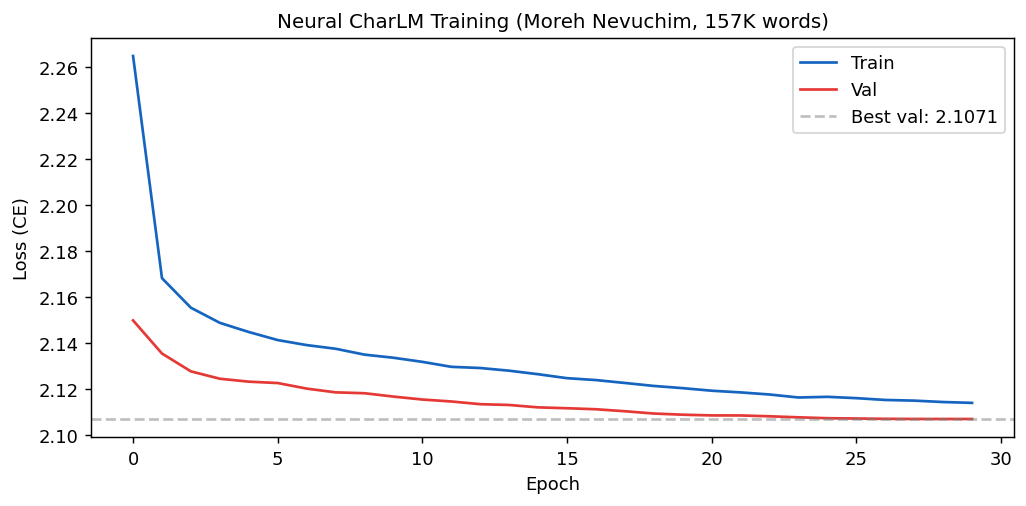

In [12]:
# ── Cell 5: Neural LM training (on FULL 157K corpus) ─────────────────

# Train/val split on the FULL corpus
rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words_full))
perm = rng_split.permutation(len(hebrew_words_full))
val_idx = set(perm[:n_val])
train_words = [hebrew_words_full[i] for i in range(len(hebrew_words_full)) if i not in val_idx]
val_words = [hebrew_words_full[i] for i in range(len(hebrew_words_full)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM on FULL Moreh Nevuchim ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

neural_lm.load_state_dict(best_state_dict)

neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training (Moreh Nevuchim, 157K words)')
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# ── Cell 6: GlyphMappingState + Scoring + Root helpers (EXTENDED) ───

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# ── Scoring functions ──

def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar(mapping_state, glyph_anchor_sets):
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping_state.mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       glyph_role, char_role, glyph_anchor_sets,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                       w_gram=1.0, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_role, char_role, glyph_anchor_sets,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                            w_gram=1.0, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role, char_role)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_gram = score_grammar(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


# ── Hard-K proposal ──
def propose_change_hard_k(state, rng, K_min=20, constrained=True, max_retries=50):
    for _ in range(max_retries):
        new, glyph = state.propose_change_tracked(rng, constrained)
        if len(set(new.mapping.values())) >= K_min:
            return new, glyph
    return None, None


# ── Root counting helpers ──
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton(mapped_word, confidences, conf_threshold, glyph_word):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if i < len(glyph_word):
            g = glyph_word[i]
            if confidences.get(g, 0) < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)

def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    return all(s == '*' or s == r for s, r in zip(skeleton, root))

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


print('Scoring functions + root helpers loaded')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

Scoring functions + root helpers loaded
Hebrew roots: 100


In [14]:
# ── Cell 7: Strategy A — Multi-Seed EM (T=3, parallel) ──────────────
import os, contextlib, io
os.environ['CUDA_VISIBLE_DEVICES'] = ''
from multiprocessing import Pool, cpu_count
import torch

# Force single-threaded torch in workers to avoid deadlock
torch.set_num_threads(1)
neural_lm.eval()

N_SEEDS = 20
T_FIXED = 3.0
SCORE_KW = dict(w_gram=2.0, w_card=0.5, K_max=20)
SAMPLE_EM = 3000
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200
N_CPUS = max(1, cpu_count() - 1)

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

# Base frequency mapping
base_mapping = init_frequency_mapping(
    palabras, VOCAB, target_chars_heb, hebrew_words,
    glyph_role, char_role_heb)

def _em_seed_worker(seed_idx):
    """Run a single EM seed. Accesses globals via fork."""
    torch.set_num_threads(1)
    rng = np.random.default_rng(42 + seed_idx * 137)
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    if seed_idx < 10:
        mapping_init = dict(base_mapping)
        glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
        for g in glyphs_to_scramble:
            role = glyph_role.get(g, '?')
            candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role] if role in ('C', 'V') else target_chars_heb
            mapping_init[g] = rng.choice(candidates)
        state.set_mapping(mapping_init)
    else:
        mapping_init = {}
        for g in VOCAB:
            role = glyph_role.get(g, '?')
            candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role] if role in ('C', 'V') else target_chars_heb
            mapping_init[g] = rng.choice(candidates)
        state.set_mapping(mapping_init)

    with torch.no_grad():
        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T_FIXED,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed_glyph = best_state.propose_change_tracked(rng, constrained=True)
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                    glyph_role, char_role_heb, glyph_anchor_sets,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True
            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))
    gram = score_grammar(best_state, glyph_anchor_sets)
    roots_found, n_matches = count_roots_quick(best_state.mapping, palabras)

    # Return only serializable data (no GlyphMappingState object)
    return {
        'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
        'n_matches': n_matches, 'elapsed': elapsed,
        'mapping': dict(best_state.mapping),  # plain dict, serializable
        'word_lps': list(best_word_lps) if best_word_lps is not None else None,
        'iter_converged': it + 1,
    }

print(f'Strategy A: {N_SEEDS} seeds, T={T_FIXED}, {SAMPLE_EM} words, {EM_ITERS} iter')
print(f'Running on {N_CPUS} CPUs...')
t0_total = time.time()
with Pool(N_CPUS) as pool:
    raw_results_a = pool.map(_em_seed_worker, range(N_SEEDS))

# Reconstruct full result objects with GlyphMappingState
multi_seed_results = []
for r in raw_results_a:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(r['mapping'])
    r['state'] = state
    if r['word_lps'] is not None:
        r['word_lps'] = np.array(r['word_lps'])
    multi_seed_results.append(r)

elapsed_total = time.time() - t0_total
print(f'Total wall time: {elapsed_total:.0f}s')

for r in multi_seed_results:
    init_type = 'freq+scramble' if r['seed'] < 10 else 'random_CV'
    print(f'  Seed {r["seed"]:2d} [{init_type:13s}]: score={r["score"]:.4f}, K={r["K_eff"]:2d}, '
          f'gram={r["grammar"]:.2f}, roots={r["n_roots"]:2d}, iter={r["iter_converged"]}, {r["elapsed"]:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Strategy A -- Summary')
print(f'{"="*60}')
df_a = pd.DataFrame([{
    'Seed': r['seed'], 'Init': 'freq' if r['seed'] < 10 else 'rand',
    'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
    'Grammar': f"{r['grammar']:.2f}", 'Roots': r['n_roots'],
    'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s"
} for r in multi_seed_results])
print(df_a.to_string(index=False))

scores_a = [r['score'] for r in multi_seed_results]
roots_a = [r['n_roots'] for r in multi_seed_results]
print(f'\nScore: mean={np.mean(scores_a):.4f}, std={np.std(scores_a):.4f}')
print(f'Roots: mean={np.mean(roots_a):.1f}, std={np.std(roots_a):.1f}, '
      f'min={min(roots_a)}, max={max(roots_a)}')


Strategy A: 20 seeds, T=3.0, 3000 words, 2000 iter
Running on 15 CPUs...
Total wall time: 935s
  Seed  0 [freq+scramble]: score=-37.4869, K=27, gram=0.83, roots= 0, iter=274, 732s
  Seed  1 [freq+scramble]: score=-38.2558, K=27, gram=1.00, roots= 1, iter=210, 601s
  Seed  2 [freq+scramble]: score=-38.8940, K=27, gram=0.83, roots= 1, iter=219, 632s
  Seed  3 [freq+scramble]: score=-37.9770, K=27, gram=1.00, roots= 0, iter=262, 706s
  Seed  4 [freq+scramble]: score=-37.9502, K=27, gram=0.83, roots= 3, iter=241, 688s
  Seed  5 [freq+scramble]: score=-39.0170, K=27, gram=0.67, roots= 3, iter=217, 629s
  Seed  6 [freq+scramble]: score=-37.8635, K=27, gram=0.83, roots= 3, iter=194, 540s
  Seed  7 [freq+scramble]: score=-37.2433, K=27, gram=0.67, roots= 0, iter=195, 574s
  Seed  8 [freq+scramble]: score=-38.4386, K=27, gram=1.00, roots= 2, iter=200, 587s
  Seed  9 [freq+scramble]: score=-38.3445, K=27, gram=1.00, roots= 3, iter=259, 742s
  Seed 10 [random_CV    ]: score=-37.6852, K=27, gram=0

In [15]:
# ── Cell 8: Strategy B — Hard-K + Low T (parallel) ──────────────────
T_VALUES_LOW = [1.5, 2.0]
K_MIN = 20
N_SEEDS_B = 5

configs_b = [(T_low, seed_idx) for T_low in T_VALUES_LOW for seed_idx in range(N_SEEDS_B)]

def _hard_k_worker(args):
    """Run a single Hard-K EM seed."""
    T_low, seed_idx = args
    torch.set_num_threads(1)
    rng = np.random.default_rng(1000 + seed_idx * 137 + int(T_low * 100))

    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    mapping_init = dict(base_mapping)
    glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
    for g in glyphs_to_scramble:
        role = glyph_role.get(g, '?')
        candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role] if role in ('C', 'V') else target_chars_heb
        mapping_init[g] = rng.choice(candidates)
    state.set_mapping(mapping_init)

    with torch.no_grad():
        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T_low,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0
        n_rejections = 0
        n_proposals_total = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                n_proposals_total += 1
                proposal, changed_glyph = propose_change_hard_k(
                    best_state, rng, K_min=K_MIN, constrained=True)
                if proposal is None:
                    n_rejections += 1
                    continue
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T_low,
                    glyph_role, char_role_heb, glyph_anchor_sets,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True
            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))
    gram = score_grammar(best_state, glyph_anchor_sets)
    roots_found, n_matches = count_roots_quick(best_state.mapping, palabras)
    reject_pct = n_rejections / max(n_proposals_total, 1)

    return {
        'T': T_low, 'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
        'n_matches': n_matches, 'elapsed': elapsed,
        'mapping': dict(best_state.mapping),
        'word_lps': list(best_word_lps) if best_word_lps is not None else None,
        'n_rejections': n_rejections, 'reject_pct': reject_pct,
        'iter_converged': it + 1,
    }

print(f'Strategy B: Hard-K (K_min={K_MIN}), T={T_VALUES_LOW}, {N_SEEDS_B} seeds per T')
print(f'Running {len(configs_b)} configs on {N_CPUS} CPUs...')
t0_total = time.time()
with Pool(N_CPUS) as pool:
    raw_results_b = pool.map(_hard_k_worker, configs_b)

hard_k_results = []
for r in raw_results_b:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(r['mapping'])
    r['state'] = state
    if r['word_lps'] is not None:
        r['word_lps'] = np.array(r['word_lps'])
    hard_k_results.append(r)

elapsed_total = time.time() - t0_total
print(f'Total wall time: {elapsed_total:.0f}s')

for r in hard_k_results:
    print(f'  T={r["T"]}, Seed {r["seed"]}: score={r["score"]:.4f}, K={r["K_eff"]:2d}, '
          f'gram={r["grammar"]:.2f}, roots={r["n_roots"]:2d}, reject={r["reject_pct"]:.1%}, {r["elapsed"]:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Strategy B -- Summary')
print(f'{"="*60}')
rows_b = []
for r in hard_k_results:
    rows_b.append({
        'T': r['T'], 'Seed': r['seed'],
        'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
        'Grammar': f"{r['grammar']:.2f}", 'Roots': r['n_roots'],
        'Reject%': f"{r['reject_pct']:.1%}",
        'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s",
    })
df_b = pd.DataFrame(rows_b)
print(df_b.to_string(index=False))


Strategy B: Hard-K (K_min=20), T=[1.5, 2.0], 5 seeds per T
Running 10 configs on 15 CPUs...
Total wall time: 527s
  T=1.5, Seed 0: score=-37.5432, K=27, gram=0.50, roots= 0, reject=0.0%, 405s
  T=1.5, Seed 1: score=-36.4139, K=27, gram=0.50, roots= 2, reject=0.0%, 369s
  T=1.5, Seed 2: score=-36.8284, K=27, gram=0.50, roots= 0, reject=0.0%, 335s
  T=1.5, Seed 3: score=-40.1480, K=27, gram=0.67, roots= 1, reject=0.0%, 434s
  T=1.5, Seed 4: score=-36.6065, K=27, gram=0.50, roots= 2, reject=0.0%, 402s
  T=2.0, Seed 0: score=-38.5940, K=27, gram=1.00, roots= 2, reject=0.0%, 368s
  T=2.0, Seed 1: score=-36.9154, K=27, gram=0.33, roots= 0, reject=0.0%, 357s
  T=2.0, Seed 2: score=-38.4366, K=27, gram=0.67, roots= 0, reject=0.0%, 342s
  T=2.0, Seed 3: score=-36.2809, K=27, gram=0.33, roots= 0, reject=0.0%, 526s
  T=2.0, Seed 4: score=-36.5303, K=27, gram=0.33, roots= 1, reject=0.0%, 488s

Strategy B -- Summary
  T  Seed    Score  K_eff Grammar  Roots Reject%  Iter Time
1.5     0 -37.5432     

In [16]:
# ── Cell 9: Best candidate selection ───────────────────────────

# Combine all runs
all_runs = []
for r in multi_seed_results:
    all_runs.append({**r, 'strategy': 'A_multi_seed', 'T': T_FIXED, 'label': f'A_s{r["seed"]}'})
for r in hard_k_results:
    all_runs.append({**r, 'strategy': 'B_hard_k', 'label': f'B_T{r["T"]}_s{r["seed"]}'})

print(f'Total runs: {len(all_runs)}')

# Filter: K_eff >= 20, grammar >= 0.8, score in top-50%
scores_all = [r['score'] for r in all_runs]
score_median = np.median(scores_all)

candidates = [r for r in all_runs
              if r['K_eff'] >= 20
              and r['grammar'] >= 0.8
              and r['score'] >= score_median]

print(f'Filtered candidates (K>=20, gram>=0.8, score>=median): {len(candidates)}')

if not candidates:
    print('No candidates meet all criteria. Relaxing: K>=15, gram>=0.5')
    candidates = [r for r in all_runs
                  if r['K_eff'] >= 15
                  and r['grammar'] >= 0.5
                  and r['score'] >= score_median]
    print(f'Relaxed candidates: {len(candidates)}')

if not candidates:
    print('Still no candidates. Using all runs.')
    candidates = all_runs

# Sort by roots (primary), then score (secondary)
candidates.sort(key=lambda r: (r['n_roots'], r['score']), reverse=True)

# Show top-5
print(f'\nTop-5 candidates:')
df_top = pd.DataFrame([{
    'Label': r['label'], 'Strategy': r['strategy'],
    'T': r['T'], 'Score': f"{r['score']:.4f}",
    'K_eff': r['K_eff'], 'Grammar': f"{r['grammar']:.2f}",
    'Roots': r['n_roots'],
} for r in candidates[:5]])
print(df_top.to_string(index=False))

# Select best
BEST = candidates[0]
print(f'\nSelected: {BEST["label"]} (strategy={BEST["strategy"]}, '
      f'T={BEST["T"]}, roots={BEST["n_roots"]}, score={BEST["score"]:.4f})')

Total runs: 30
Filtered candidates (K>=20, gram>=0.8, score>=median): 6

Top-5 candidates:
Label     Strategy   T    Score  K_eff Grammar  Roots
A_s15 A_multi_seed 3.0 -37.7032     27    1.00      3
A_s18 A_multi_seed 3.0 -37.7304     27    1.00      3
A_s11 A_multi_seed 3.0 -37.7304     27    1.00      3
 A_s6 A_multi_seed 3.0 -37.8635     27    0.83      3
A_s10 A_multi_seed 3.0 -37.6852     27    0.83      1

Selected: A_s15 (strategy=A_multi_seed, T=3.0, roots=3, score=-37.7032)


In [17]:
# ── Cell 10: MCMC multi-chain (parallel) ──────────────────────────────

T_mcmc = BEST['T']
USE_HARD_K = BEST['strategy'] == 'B_hard_k'
print(f'MCMC with: T={T_mcmc}, hard_K={USE_HARD_K}')

MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm, glyph_role, char_role,
                        glyph_anchor_sets, glyph_word_idx, n_cal=300,
                        target_accept=0.35, use_hard_k=False, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    with torch.no_grad():
        cal_score, cal_word_lps = score_total_neural(
            state, words_sample, neural_lm, T_lm,
            glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
        for _ in range(n_cal):
            if use_hard_k:
                prop, changed = propose_change_hard_k(cal_state, rng_cal, K_min=K_MIN)
                if prop is None:
                    continue
            else:
                prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
            ps, pw = score_total_incremental(
                prop, changed, words_sample, neural_lm, T_lm,
                glyph_role, char_role, glyph_anchor_sets,
                glyph_word_idx, cal_word_lps, **score_kwargs)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            cal_state = prop
            cal_score = ps
            cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp(
    BEST['state'], words_mcmc, neural_lm, T_mcmc,
    glyph_role, char_role_heb, glyph_anchor_sets,
    glyph_word_idx_mcmc, use_hard_k=USE_HARD_K, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Store mapping as plain dict for fork safety
_MCMC_BEST_MAPPING = dict(BEST['state'].mapping)

def _mcmc_chain_worker(seed):
    """Run a single MCMC chain."""
    torch.set_num_threads(1)
    rng_ch = np.random.default_rng(seed)
    current = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    current.set_mapping(dict(_MCMC_BEST_MAPPING))

    with torch.no_grad():
        current_score, current_word_lps = score_total_neural(
            current, words_mcmc, neural_lm, T_mcmc,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)

        best_ch = current
        best_ch_score = current_score
        chain_scores = [current_score]
        chain_mappings = [dict(current.mapping)]
        accepted = 0
        _thin = 0

        for it in range(N_ITER):
            if it < BURN_IN:
                frac = it / BURN_IN
                T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
            else:
                frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
                T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

            if USE_HARD_K:
                proposal, changed_glyph = propose_change_hard_k(current, rng_ch, K_min=K_MIN)
                if proposal is None:
                    chain_scores.append(current_score)
                    _thin += 1
                    if _thin % THIN == 0:
                        chain_mappings.append(dict(current.mapping))
                    continue
            else:
                proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)

            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_mcmc, neural_lm, T_mcmc,
                glyph_role, char_role_heb, glyph_anchor_sets,
                glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

            delta = prop_score - current_score
            if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
                current = proposal
                current_score = prop_score
                current_word_lps = prop_word_lps
                accepted += 1
                if current_score > best_ch_score:
                    best_ch = current
                    best_ch_score = current_score

            chain_scores.append(current_score)
            _thin += 1
            if _thin % THIN == 0:
                chain_mappings.append(dict(current.mapping))

    return {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_mapping': dict(best_ch.mapping),
        'best_score': best_ch_score,
    }

print(f'Running {N_CHAINS} MCMC chains on {N_CPUS} CPUs...')
t0_mcmc = time.time()
with Pool(N_CPUS) as pool:
    raw_mcmc = pool.map(_mcmc_chain_worker, SEEDS_MCMC)

# Reconstruct
mcmc_chains = []
global_best = None
global_best_score = -np.inf
for ch in raw_mcmc:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(ch['best_mapping'])
    ch['best_state'] = state
    mcmc_chains.append(ch)
    if ch['best_score'] > global_best_score:
        global_best_score = ch['best_score']
        global_best = state

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

elapsed_mcmc = time.time() - t0_mcmc
print(f'\nMCMC completed in {elapsed_mcmc/60:.1f} minutes')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')


MCMC with: T=3.0, hard_K=False
Calibrated T_anneal: 0.000623 -> 0.00000623
Running 4 MCMC chains on 15 CPUs...

MCMC completed in 1.8 minutes
Best score: -37.7028
K_eff: 26
  Chain 1: accept=28.1%, best=-37.7031
  Chain 2: accept=28.3%, best=-37.7032
  Chain 3: accept=27.8%, best=-37.7028
  Chain 4: accept=30.2%, best=-37.7032


In [18]:
# ── Cell 11: Validation (5 tests) ────────────────────────────────────

# ── Posterior + R-hat ──
def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_v2, rhat_v2, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_v2.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

conf_v2 = {}
for g, dist in posterior_v2.items():
    conf_v2[g] = max(dist.values()) if dist else 0.0

mapping_v2 = dict(global_best.mapping)

# ── Helpers ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_v2.items():
    groups[c].append(g)
all_glyphs = list(mapping_v2.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_v2 = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_v2.set_mapping(mapping_v2)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_v2.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_v2.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_v2}
    ss = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    ss.set_mapping(shuf)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

word_freq = Counter(tuple(w) for w in palabras)
top_words = word_freq.most_common(200)
roots_matched = set()
n_matches = 0
skeletons_seen = Counter()

for word_tuple, freq in top_words:
    word_glyphs = list(word_tuple)
    mapped = [mapping_v2.get(g, '?') for g in word_glyphs]
    skeleton = extract_skeleton(mapped, conf_v2, 0.70, word_glyphs)
    if len(skeleton) < 3:
        continue
    for i in range(len(skeleton) - 2):
        sub = skeleton[i:i+3]
        skeletons_seen[sub] += 1
        for root in HEBREW_ROOTS:
            if match_skeleton_to_root(sub, root):
                roots_matched.add(root)
                n_matches += 1

n_roots_total = len(HEBREW_ROOTS)
unique_skels = len(skeletons_seen)
n_wc_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
expected = n_roots_total * (1/len(HEBREW_CONSONANTS_SET))**max(3-n_wc_mean, 0.5) * unique_skels
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
K_used = len(set(mapping_v2.values()))
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Chars used: {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Grammar anchors
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Grammar anchor consistency')
print('='*60)
n_comply, n_total_a = 0, 0
for g, anchor_set in glyph_anchor_sets.items():
    if not anchor_set:
        continue
    n_total_a += 1
    if mapping_v2.get(g) in anchor_set:
        n_comply += 1
pct_anchor = n_comply / max(n_total_a, 1)
test5_pass = pct_anchor > 0.6
print(f'Anchors: {n_comply}/{n_total_a} ({pct_anchor:.0%})')
print(f'Test 5: {"PASS" if pct_anchor > 0.6 else ("MARGINAL" if pct_anchor > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Grammar anchors', 'Value': f'{pct_anchor:.0%}',
     'Verdict': verdict(pct_anchor, 0.6, 0.4)},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 54.2% of 166 glyphs

Test 1: Collapse coherence (JSD z-scores)
mean_z=-0.90, STRUCTURED=0, DEGENERATE=4
Test 1: PASS (z > -1.0)

Test 2: N-gram realism


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7364, percentile=13.0%
Test 2: MARGINAL

Test 3: Hebrew roots
Roots matched: 3, enrichment: 35.0x
Test 3: FAIL

Test 4: Cardinality
Chars used: 26/27 (ratio=0.96)
Test 4: PASS

Test 5: Grammar anchor consistency
Anchors: 12/12 (100%)
Test 5: PASS

SCORECARD
                Test   Value  Verdict
 1. Collapse z-score   -0.90     PASS
2. N-gram percentile   13.0% MARGINAL
    3. Root matching 3 roots     FAIL
4. Cardinality ratio    0.96     PASS
  5. Grammar anchors    100%     PASS

Total: 3 PASS / 1 MARGINAL / 1 FAIL


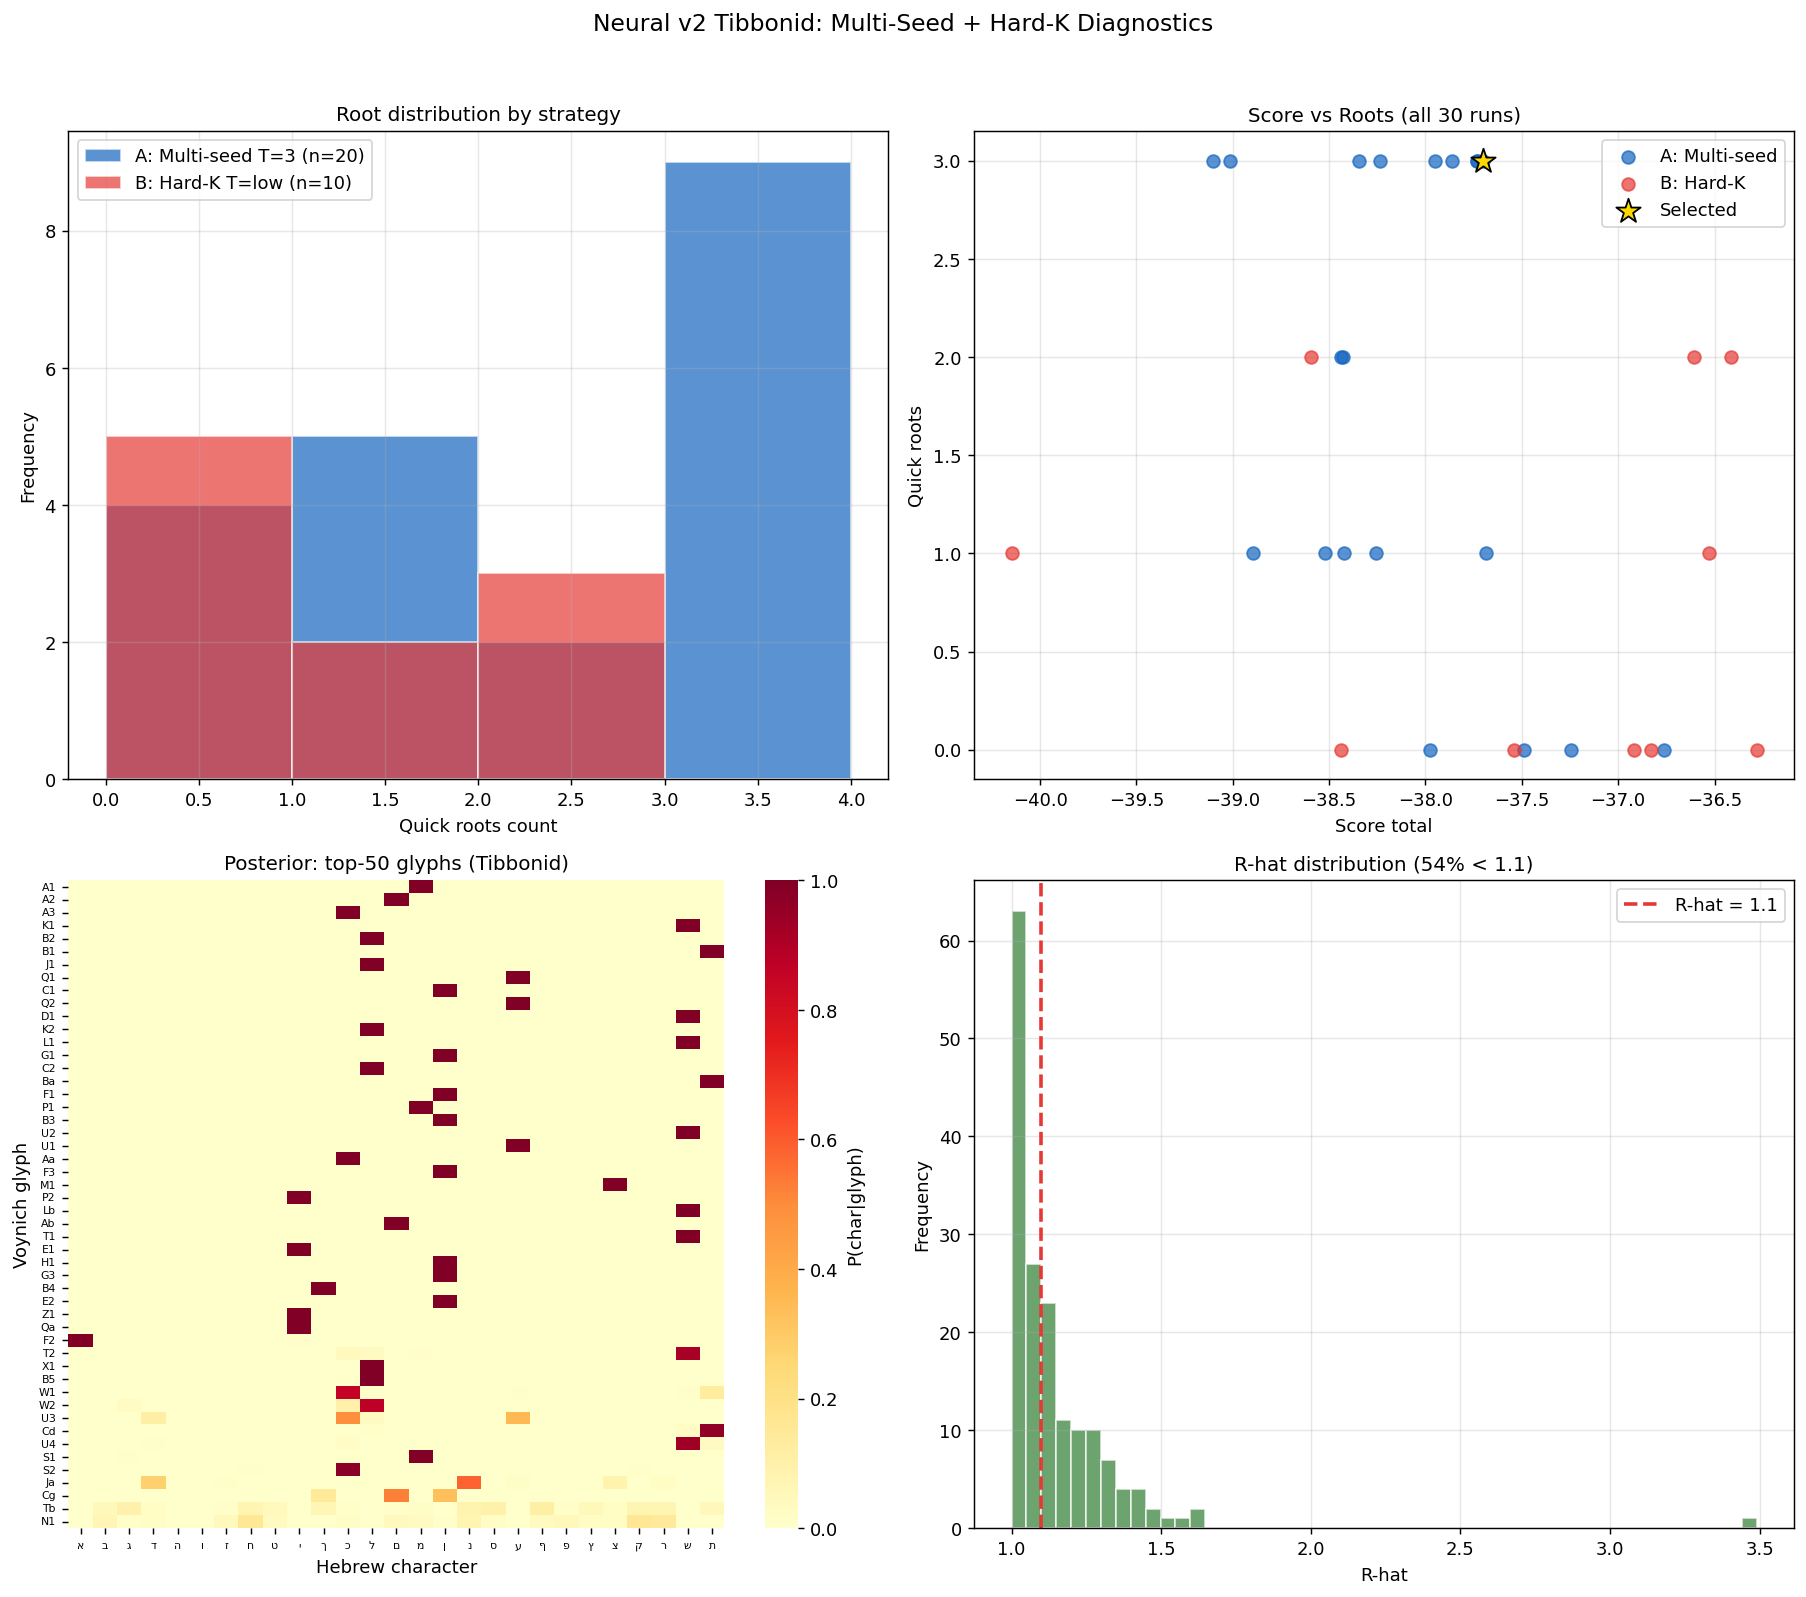

In [19]:
# ── Cell 12: Visualisations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Distribution of roots across 20 seeds (histogram)
ax = axes[0, 0]
roots_a = [r['n_roots'] for r in multi_seed_results]
roots_b = [r['n_roots'] for r in hard_k_results]
ax.hist(roots_a, bins=range(0, max(roots_a + roots_b) + 2), alpha=0.7,
        color='#1565C0', label=f'A: Multi-seed T=3 (n={len(roots_a)})', edgecolor='white')
ax.hist(roots_b, bins=range(0, max(roots_a + roots_b) + 2), alpha=0.7,
        color='#E53935', label=f'B: Hard-K T=low (n={len(roots_b)})', edgecolor='white')
ax.set_xlabel('Quick roots count')
ax.set_ylabel('Frequency')
ax.set_title('Root distribution by strategy')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Score vs roots scatter (30 runs)
ax = axes[0, 1]
scores_a_vals = [r['score'] for r in multi_seed_results]
roots_a_vals = [r['n_roots'] for r in multi_seed_results]
scores_b_vals = [r['score'] for r in hard_k_results]
roots_b_vals = [r['n_roots'] for r in hard_k_results]
ax.scatter(scores_a_vals, roots_a_vals, c='#1565C0', s=50, alpha=0.7, label='A: Multi-seed', zorder=3)
ax.scatter(scores_b_vals, roots_b_vals, c='#E53935', s=50, alpha=0.7, label='B: Hard-K', zorder=3)
ax.scatter([BEST['score']], [BEST['n_roots']], c='gold', s=200, marker='*',
           edgecolors='black', linewidths=1, zorder=5, label='Selected')
ax.set_xlabel('Score total')
ax.set_ylabel('Quick roots')
ax.set_title('Score vs Roots (all 30 runs)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Heatmap posterior (top-50 glyphs)
ax = axes[1, 0]
top50_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:50]
heatmap_data = np.zeros((len(top50_glyphs), len(target_chars_heb)))
for i, g in enumerate(top50_glyphs):
    if g in posterior_v2:
        for c, prob in posterior_v2[g].items():
            if c in target_chars_heb:
                j = target_chars_heb.index(c)
                heatmap_data[i, j] = prob

sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd',
            xticklabels=target_chars_heb, yticklabels=top50_glyphs,
            cbar_kws={'label': 'P(char|glyph)'})
ax.set_xlabel('Hebrew character')
ax.set_ylabel('Voynich glyph')
ax.set_title('Posterior: top-50 glyphs (Tibbonid)')
ax.tick_params(labelsize=6)

# Plot 4: R-hat distribution
ax = axes[1, 1]
rhat_finite = [v for v in rhat_vals if v < 5.0]
ax.hist(rhat_finite, bins=50, color='#2E7D32', alpha=0.7, edgecolor='white')
ax.axvline(1.1, color='#E53935', linestyle='--', linewidth=2, label='R-hat = 1.1')
ax.set_xlabel('R-hat')
ax.set_ylabel('Frequency')
ax.set_title(f'R-hat distribution ({pct_converged:.0f}% < 1.1)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Neural v2 Tibbonid: Multi-Seed + Hard-K Diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [20]:
# ── Cell 13: Export results -> tibbonid_resultados.json ────────

mapping_serializable = {g: c for g, c in mapping_v2.items()}

posterior_serializable = {}
for g, dist in posterior_v2.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

resultados = {
    'metadata': {
        'notebook': '33_tibbonid_hebrew.ipynb',
        'model': 'neural_lstm_multi_seed_hard_k',
        'language': 'hebrew_tibbonid',
        'corpus': 'Moreh Nevuchim (Ibn Tibbon translation)',
        'description': 'Neural v2 pipeline against Tibbonid/philosophical Hebrew (Moreh Nevuchim)',
    },
    'corpus_stats': {
        'n_words_full': len(hebrew_words_full),
        'n_words_sub': len(hebrew_words),
        'n_chars': len(target_chars_heb),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
        'trained_on': 'full 157K words',
    },
    'multi_seed_results': [{
        'seed': r['seed'], 'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']), 'grammar': round(float(r['grammar']), 3),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in multi_seed_results],
    'hard_k_results': [{
        'T': float(r['T']), 'seed': int(r['seed']),
        'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']), 'grammar': round(float(r['grammar']), 3),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'reject_pct': round(float(r['reject_pct']), 3),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in hard_k_results],
    'best_candidate': {
        'label': BEST['label'],
        'strategy': BEST['strategy'],
        'T': float(BEST['T']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'grammar': round(float(BEST['grammar']), 3),
        'n_roots_quick': int(BEST['n_roots']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'grammar_anchor_pct': round(float(pct_anchor), 3),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_v2.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'multi_seed_summary': {
        'n_seeds': N_SEEDS,
        'score_mean': round(float(np.mean([r['score'] for r in multi_seed_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in multi_seed_results])), 4),
        'roots_mean': round(float(np.mean([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_std': round(float(np.std([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_max': int(max(r['n_roots'] for r in multi_seed_results)),
    },
    'hard_k_summary': {
        'K_min': K_MIN,
        'T_values': T_VALUES_LOW,
        'n_seeds_per_T': N_SEEDS_B,
        'roots_mean': round(float(np.mean([r['n_roots'] for r in hard_k_results])), 1),
        'roots_max': int(max(r['n_roots'] for r in hard_k_results)),
        'mean_reject_pct': round(float(np.mean([r['reject_pct'] for r in hard_k_results])), 3),
    },
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

with open('tibbonid_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to tibbonid_resultados.json')
print(f'Keys: {list(resultados.keys())}')

print(f'\n-- Final summary --')
print(f'Model: Neural v2 (Multi-Seed + Hard-K) on Moreh Nevuchim')
print(f'Best candidate: {BEST["label"]} (T={BEST["T"]})')
print(f'Quick roots (pre-MCMC): {BEST["n_roots"]}')
print(f'Validated roots (post-MCMC): {len(roots_matched)}')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')
print(f'R-hat convergence: {pct_converged:.0f}%')
print(f'\nRoot distribution (20 seeds): '
      f'{np.mean([r["n_roots"] for r in multi_seed_results]):.1f} +/- '
      f'{np.std([r["n_roots"] for r in multi_seed_results]):.1f}')

Results exported to tibbonid_resultados.json
Keys: ['metadata', 'corpus_stats', 'neural_lm', 'multi_seed_results', 'hard_k_results', 'best_candidate', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping', 'posterior_top', 'rhat', 'multi_seed_summary', 'hard_k_summary']

-- Final summary --
Model: Neural v2 (Multi-Seed + Hard-K) on Moreh Nevuchim
Best candidate: A_s15 (T=3.0)
Quick roots (pre-MCMC): 3
Validated roots (post-MCMC): 3
Scorecard: 3 PASS / 1 MARGINAL / 1 FAIL
R-hat convergence: 54%

Root distribution (20 seeds): 1.8 +/- 1.2


In [21]:
# ── Cell 14: Comparison with Torah-based Neural v2 ──────────────────

print('='*70)
print('COMPARISON: Tibbonid (Moreh Nevuchim) vs Torah (Neural v2)')
print('='*70)

# Load Torah results
torah_results = {}
try:
    with open('neural_v2_resultados.json', 'r') as f:
        torah_results = json.load(f)
    print('Loaded neural_v2_resultados.json (Torah)')
except FileNotFoundError:
    print('WARNING: neural_v2_resultados.json not found')

# Extract Torah metrics
torah_ngram = torah_results.get('validation_details', {}).get('ngram_percentile', None)
torah_roots = torah_results.get('validation_details', {}).get('roots_matched', None)
torah_rhat = torah_results.get('mcmc_results', {}).get('pct_converged_rhat', None)
torah_collapse_z = torah_results.get('validation_details', {}).get('collapse_mean_z', None)
torah_K_ratio = torah_results.get('validation_details', {}).get('cardinality_ratio', None)
torah_grammar = torah_results.get('validation_details', {}).get('grammar_anchor_pct', None)
torah_val_loss = torah_results.get('neural_lm', {}).get('best_val_loss', None)
torah_scorecard = torah_results.get('scorecard_summary', None)
torah_roots_mean = torah_results.get('multi_seed_summary', {}).get('roots_mean', None)
torah_roots_std = torah_results.get('multi_seed_summary', {}).get('roots_std', None)
torah_score_mean = torah_results.get('multi_seed_summary', {}).get('score_mean', None)

# Tibbonid metrics
tibb_roots_mean = np.mean([r['n_roots'] for r in multi_seed_results])
tibb_roots_std = np.std([r['n_roots'] for r in multi_seed_results])
tibb_score_mean = np.mean([r['score'] for r in multi_seed_results])

def fmt(val, decimals=1):
    if val is None:
        return '--'
    if isinstance(val, str):
        return val
    return f'{val:.{decimals}f}'

comparison_rows = [
    {'Metric': 'LM val_loss',       'Torah': fmt(torah_val_loss, 4), 'Tibbonid': f'{best_val_loss:.4f}'},
    {'Metric': 'N-gram %ile',       'Torah': fmt(torah_ngram, 1),    'Tibbonid': f'{pct_ngram:.1f}'},
    {'Metric': 'Roots matched',     'Torah': fmt(torah_roots, 0),    'Tibbonid': f'{len(roots_matched)}'},
    {'Metric': 'Roots (20 seeds)',  'Torah': f'{fmt(torah_roots_mean,1)} +/- {fmt(torah_roots_std,1)}',
                                     'Tibbonid': f'{tibb_roots_mean:.1f} +/- {tibb_roots_std:.1f}'},
    {'Metric': 'Collapse z-score',  'Torah': fmt(torah_collapse_z, 2), 'Tibbonid': f'{mean_z:.2f}'},
    {'Metric': 'R-hat < 1.1 %',    'Torah': fmt(torah_rhat, 1),     'Tibbonid': f'{pct_converged:.1f}'},
    {'Metric': 'Cardinality ratio', 'Torah': fmt(torah_K_ratio, 3),  'Tibbonid': f'{K_ratio:.3f}'},
    {'Metric': 'Grammar anchor %',  'Torah': fmt(torah_grammar, 3),  'Tibbonid': f'{pct_anchor:.3f}'},
    {'Metric': 'Score mean (20s)',  'Torah': fmt(torah_score_mean, 4), 'Tibbonid': f'{tibb_score_mean:.4f}'},
    {'Metric': 'Scorecard',          'Torah': torah_scorecard or '--',
                                      'Tibbonid': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL'},
]

df_comp = pd.DataFrame(comparison_rows)
print(df_comp.to_string(index=False))

print('\n-- Interpretation --')
print('If Tibbonid results are comparable to Torah, this confirms the barrier')
print('is structural (encoding mechanism) rather than register-specific.')
print('If Tibbonid is significantly worse, the Voynich may be closer to')
print('biblical Hebrew than to medieval philosophical Hebrew.')

COMPARISON: Tibbonid (Moreh Nevuchim) vs Torah (Neural v2)
Loaded neural_v2_resultados.json (Torah)
           Metric                        Torah                     Tibbonid
      LM val_loss                       2.0039                       2.1071
      N-gram %ile                         68.0                         13.0
    Roots matched                            3                            3
 Roots (20 seeds)                  1.4 +/- 1.1                  1.8 +/- 1.2
 Collapse z-score                        -0.94                        -0.90
    R-hat < 1.1 %                         71.1                         54.2
Cardinality ratio                        0.926                        0.963
 Grammar anchor %                        1.000                        1.000
 Score mean (20s)                     -36.3378                     -38.0895
        Scorecard 4 PASS / 0 MARGINAL / 1 FAIL 3 PASS / 1 MARGINAL / 1 FAIL

-- Interpretation --
If Tibbonid results are comparable to Tora